### Contexto e Objetivo 

Aplicar e apresentar estatística descritiva do dataset: new_logs.csv

Aplicar 4 dos algoritmos estudados, justificar escolhas e demonstrar as técnicas vistas na disciplina no dataset:

-    K-Means; 
-    Hierárquico; 
-    DBSCAN; 
-    Avaliação de Clusters.
-    Análise de Componentes Principais (PCA); 
-    Técnicas de seleção de características; 
-    T-SNE.
-    Apriori; 
-    FP-Growth.

# Resumo Executivo: Análise Comportamental e Detecção de Anomalias em Logs de Firewall

Este projeto prático aplica técnicas avançadas de **Aprendizado Não Supervisionado** sobre um conjunto de dados real de logs de tráfego de rede corporativa (`new_logs.csv`), atendendo rigorosamente aos critérios metodológicos e avaliativos estabelecidos nas diretrizes acadêmicas. O objetivo central é identificar padrões ocultos de conexões e segregar de forma automatizada o tráfego regular de potenciais ameaças ou anomalias de segurança cibernética (como *Port Scanning* ou ataques de negação de serviço), sem a necessidade de rótulos prévios (*labels*).

O desenvolvimento foi estruturado através de um pipeline científico ponta a ponta dividido nas seguintes fases:

1. **Saneamento e Engenharia de Atributos:** Extração de estatísticas descritivas e transformação dos logs transacionais em uma matriz de comportamento focada no **IP de Origem (`Src IP`)**, gerando atributos explicativos (volumetrias, taxas de rejeição pelo firewall e diversidade de portas visadas).
2. **Seleção de Características e Normalização:** Mitigação de ruídos geométricos e redundâncias matemáticas, através de filtros de *Variance Threshold* e eliminação de multicolinearidade por matriz de correlação absoluta, seguido da padronização *Z-Score*.
3. **Modelagem por Algoritmos de Partição e Densidade:** Implementação comparativa dos algoritmos **K-Means** (otimizado via Método do Cotovelo e Silhueta), **Agrupamento Hierárquico** (validado por correlação cofenética e análise de dendrograma) e **DBSCAN** (parametrizado via gráfico de *K-Distance* e atuando como um isolador nativo de anomalias/ruídos).
4. **Avaliação Quantitativa e Redução de Dimensionalidade:** Consolidação unificada de métricas estruturais (*Silhouette Coefficient*, *Davies-Bouldin Index* e *Calinski-Harabasz Index*), acompanhada de validações visuais e qualitativas através de projeções lineares (**PCA**) e não-lineares (**t-SNE** com calibragem dinâmica de perplexidade).
5. **Mineração de Regras de Associação:** Aplicação dos algoritmos **Apriori** e **FP-Growth** (otimizado via árvore de padrões *FP-Tree*) sobre a matriz transacional booleana para descobrir regras implícitas de disparo de políticas de segurança na rede corporativa.

Os resultados culminam em uma tabela de perfilamento comportamental por centróides, convertendo dados matemáticos abstratos em inteligência cibernética disponível para auditoria de redes e respostas a incidentes de segurança.


In [2]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'--> Dispositivo em uso: {str(device).upper()}')

--> Dispositivo em uso: CUDA


### Justificativa de Saneamento de Dados e Engenharia de Atributos:

Os logs de firewall brutos são, por natureza, transacionais, contínuos e altamente ruidosos. Aplicar algoritmos de aprendizado não supervisionado diretamente neles geraria distorções matemáticas graves, pois, analisaríamos "eventos isolados" e não o "comportamento dos agentes". 

Por essa razão, realizei três etapas fundamentais de preparação baseadas nas técnicas de Machine Learning:

1. **Saneamento Inicial (Data Cleaning):** Removi os registros com dados ausentes em colunas críticas (`Src IP`, `Dst IP`, `Dst port`) e tratei as anomalias temporais, garantindo a integridade física da base.
2. **Mudança de Perspectiva (Agregação Comportamental):** Agrupei o dataset tendo como chave o **IP de Origem (`Src IP`)**. No aprendizado não supervisionado aplicado à cibersegurança, cada IP passa a ser o nosso objeto de estudo (instância), permitindo rastrear o comportamento histórico daquela máquina na rede.
3. **Engenharia de Atributos (Feature Engineering):** Criei métricas sintéticas explicativas para o modelo, tais como:

   * `Qtd_Portas_verificadas`: Essencial para identificar varreduras automatizadas (*Port Scanning*).
   * `Taxa_Rejeicao`: Mede a agressividade do IP contra as políticas de segurança da empresa.
   * `log_Vol_Total`: Suaviza a escala de volumetria usando transformação logarítmica, impedindo que IPs legítimos, com tráfego muito alto quebrem a estabilidade geométrica dos clusters.


--- Carregamento do DataSet, Saneamento e Estatística Descritiva ---

 -> Sucesso: Arquivo carregado localmente! Formato original: (200, 20)

 >>>>> 1. ESTATÍSTICA DESCRITIVA DA BASE (LOGS DO FIREWALL) <<<<<

-> Período temporal analisado: de 2024-07-06 12:24:56 até 2024-07-06 12:29:34
-> Total de IPs de Origem Únicos na rede: 24
-> Total de IPs de Destino Únicos na rede: 58

 Principais Regras de Firewall Acionadas (Frequência Absoluta e Relativa):


,Ocorrências,Percentual (%)
Firewall rule name,,
LAN-2-WAN,72,36.363636
WindowsUpdate-2-WAN,35,17.676768
DMZ-to-WAN,31,15.656566
WebNat,21,10.606061
IT-2-WAN,16,8.080808



 Distribuição das Portas de Destino Mais Visadas:


,Volume de Acessos
Dst port,
443,87
53,80
80,23
123,7
0,1


 >>>>> 2. ENGENHARIA DE ATRIBUTOS COMPORTAMENTAIS POR IP <<<<<

-> Agrupando tráfego por IP de Origem ('Src IP') para modelagem...

 >>>>> 3. ESTATÍSTICA DESCRITIVA DO DATASET AGREGADO (Comportamento por IP) <<<<<



,count,mean,std,min,25%,50%,75%,max
Vol_Total_Logs,24.0,8.333333,15.810472,1.000000,1.000000,3.000000,8.250000,75.000000
Qtd_Destinos_Distintos,24.0,3.041667,5.706435,1.000000,1.000000,1.000000,2.000000,28.000000
Qtd_Portas_Verificadas,24.0,1.333333,0.916831,1.000000,1.000000,1.000000,1.000000,5.000000
Taxa_Rejeicao,24.0,0.084444,0.282040,0.000000,0.000000,0.000000,0.000000,1.000000
Conexoes_por_Destino,24.0,3.503057,6.077528,0.909091,0.909091,1.693405,3.798701,30.909091



 Matriz comportamental criada com sucesso! Shape final de modelagem: (24, 10)

 Gerando Gráficos da Distribuição do Volume dos Logs...


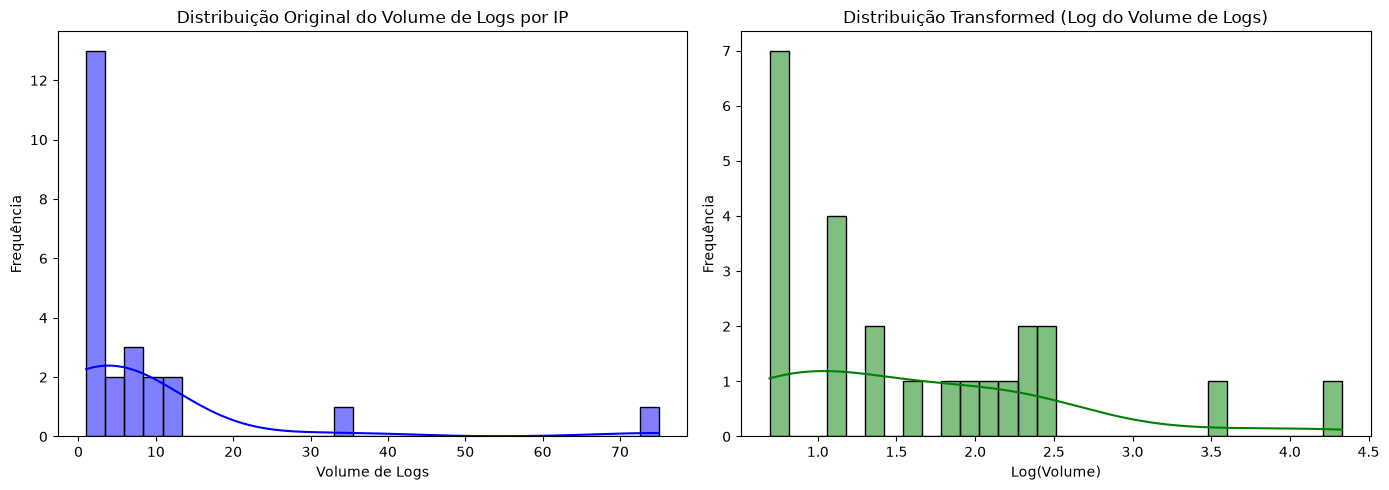


 Amostra final das novas colunas preparadas para o modelo não supervisionado:


,Src IP,Vol_Total_Logs,Qtd_Portas_Verificadas,Taxa_Rejeicao,log_Vol_Total
0,0.0.0.0,1,1,1.0,0.693147
1,104.28.62.95,2,1,0.0,1.098612
2,159.192.104.79,1,1,1.0,0.693147
3,172.17.17.10,7,1,0.0,2.079442
4,172.17.17.130,8,5,0.0,2.197225


In [3]:
print("--- Carregamento do DataSet, Saneamento e Estatística Descritiva ---\n")

# CONFIGURAÇÃO DO CAMINHO LOCAL DO DATASET )
PATH_LOCAL_DATASET = 'new_logs.csv'

# 1. LEITURA DO ARQUIVO LOCAL
try:
    df_real = pd.read_csv(PATH_LOCAL_DATASET, sep=',') 
    print(f" -> Sucesso: Arquivo carregado localmente! Formato original: {df_real.shape}\n")
except Exception as e:
    print(f" Erro Fatal: Não foi possível ler o arquivo '{PATH_LOCAL_DATASET}'. Verifique se ele está na mesma pasta que o código.")
    raise e

# 2. SANEAMENTO E LIMPEZA DE DADOS (Data Cleaning)
df_real = df_real.dropna(subset=['Src IP', 'Dst IP', 'Dst port'])

# Tratamento temporal dos logs
df_real['Time'] = pd.to_datetime(df_real['Time'], errors='coerce')
df_real = df_real.dropna(subset=['Time'])

# Garantindo a tipagem correta das portas e volumetrias de rede
df_real['Dst port'] = df_real['Dst port'].astype(int)
df_real['Src port'] = pd.to_numeric(df_real['Src port'], errors='coerce').fillna(-1).astype(int)
df_real['Log occurrence'] = pd.to_numeric(df_real['Log occurrence'], errors='coerce').fillna(1).astype(int)

# 3. ESTATÍSTICA DESCRITIVA DA BASE 
print(" >>>>> 1. ESTATÍSTICA DESCRITIVA DA BASE (LOGS DO FIREWALL) <<<<<\n")
print(f"-> Período temporal analisado: de {df_real['Time'].min()} até {df_real['Time'].max()}")
print(f"-> Total de IPs de Origem Únicos na rede: {df_real['Src IP'].nunique()}")
print(f"-> Total de IPs de Destino Únicos na rede: {df_real['Dst IP'].nunique()}")

print("\n Principais Regras de Firewall Acionadas (Frequência Absoluta e Relativa):")
dist_regras = df_real['Firewall rule name'].value_counts()
dist_regras_pct = df_real['Firewall rule name'].value_counts(normalize=True) * 100
df_dist_regras = pd.DataFrame({'Ocorrências': dist_regras, 'Percentual (%)': dist_regras_pct})
display(df_dist_regras.head(5))

print("\n Distribuição das Portas de Destino Mais Visadas:")
display(df_real['Dst port'].value_counts().head(5).to_frame(name='Volume de Acessos'))

# 4. ENGENHARIA DE ATRIBUTOS 
print(" >>>>> 2. ENGENHARIA DE ATRIBUTOS COMPORTAMENTAIS POR IP <<<<<\n")
print("-> Agrupando tráfego por IP de Origem ('Src IP') para modelagem...\n")

df_behavior = df_real.groupby('Src IP').agg({
    'Log occurrence': 'sum',                        # Volume total de requisições do IP
    'Dst IP': 'nunique',                            # Quantidade de servidores que ele tentou acessar
    'Dst port': 'nunique',                          # Quantidade de portas diferentes que ele varreu
    'Firewall rule name': 'nunique',                # Quantidade de regras diferentes que ele ativou
    'Log subtype': lambda x: (x == 'Allowed').sum() # Quantidade de acessos que o firewall permitiu
}).reset_index()

df_behavior.columns = ['Src IP', 'Vol_Total_Logs', 'Qtd_Destinos_Distintos', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Acessos_Permitidos']

# Criando métricas normalizadas essenciais para detecção de anomalias
df_behavior['Taxa_Permissao'] = df_behavior['Acessos_Permitidos'] / df_behavior['Vol_Total_Logs']
df_behavior['Taxa_Rejeicao'] = 1.0 - df_behavior['Taxa_Permissao']
df_behavior['log_Vol_Total'] = np.log1p(df_behavior['Vol_Total_Logs'])
df_behavior['Conexoes_por_Destino'] = df_behavior['Vol_Total_Logs'] / (df_behavior['Qtd_Destinos_Distintos'] + 0.1)

# 5. ESTATÍSTICA DESCRITIVA DA MATRIZ COMPORTAMENTAL 
print(" >>>>> 3. ESTATÍSTICA DESCRITIVA DO DATASET AGREGADO (Comportamento por IP) <<<<<\n")
COLS_DESCRITIVAS = ['Vol_Total_Logs', 'Qtd_Destinos_Distintos', 'Qtd_Portas_Verificadas', 'Taxa_Rejeicao', 'Conexoes_por_Destino']
display(df_behavior[COLS_DESCRITIVAS].describe().T)

print(f"\n Matriz comportamental criada com sucesso! Shape final de modelagem: {df_behavior.shape}")

# 6. GERANDO OS GRÁFICOS DA DISTRIBUIÇÃO DO VOLUME DE LOGS
print("\n Gerando Gráficos da Distribuição do Volume dos Logs...")
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_behavior['Vol_Total_Logs'], kde=True, color='blue', bins=30)
plt.title('Distribuição Original do Volume de Logs por IP')
plt.xlabel('Volume de Logs')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_behavior['log_Vol_Total'], kde=True, color='green', bins=30)
plt.title('Distribuição Transformed (Log do Volume de Logs)')
plt.xlabel('Log(Volume)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

# 7. EXIBIÇÃO DA AMOSTRA FINAL SOLICITADA
print("\n Amostra final das novas colunas preparadas para o modelo não supervisionado:")
display(df_behavior[['Src IP', 'Vol_Total_Logs', 'Qtd_Portas_Verificadas', 'Taxa_Rejeicao', 'log_Vol_Total']].head())


### Justificativa para Seleção de Características (Feature Selection):

No aprendizado não supervisionado focado em segurança de rede, incluir características redundantes ou sem variabilidade degrada drasticamente a performance dos algoritmos de agrupamento (Clustering). Como não possuímos um rótulo alvo (label), aplicamos duas abordagens estatísticas independentes sobre a matriz comportamental bruta:

1. **Limiar de Variância (Variance Threshold):** Remove recursos que se mantêm praticamente constantes, entre todos os IPs de origem. Atributos sem variabilidade funcionam como ruído geométrico no cálculo de distâncias euclidianas.
2. **Análise de Multicolinearidade (Matriz de Correlação):** Se duas métricas de tráfego possuem uma correlação linear muito forte (acima de 0.85), significa que ambas medem o mesmo fenômeno físico na rede. Manter as duas faria algoritmos como o K-Means darem "peso duplo" a um único comportamento, distorcendo o formato dos clusters.


--- [Feature Selection] Técnicas de Seleção de Características Não Supervisionadas ---
 --> Filtro de Variância concluído.
     -> Atributos mantidos: ['Vol_Total_Logs', 'Qtd_Destinos_Distintos', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Acessos_Permitidos', 'Taxa_Rejeicao', 'Conexoes_por_Destino']
     -> Atributos eliminados (baixa variância): []


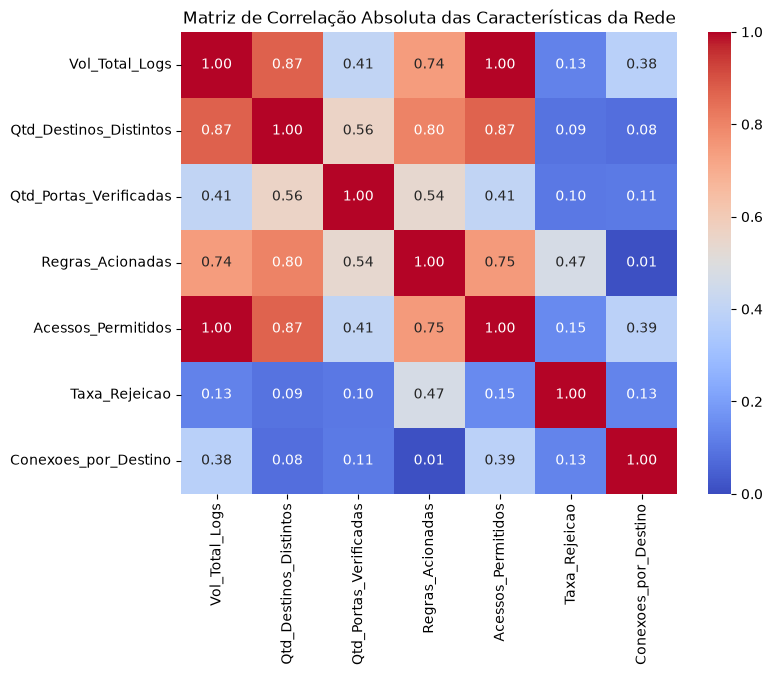


 --> Filtro de Multicolinearidade (Limiar > 0.85):

     -> Atributos sugeridos para exclusão devido à redundância: ['Qtd_Destinos_Distintos', 'Acessos_Permitidos']

 Conjunto Final de Características Selecionadas: ['Vol_Total_Logs', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Taxa_Rejeicao', 'Conexoes_por_Destino']


In [4]:
from sklearn.feature_selection import VarianceThreshold
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- [Feature Selection] Técnicas de Seleção de Características Não Supervisionadas ---")

# 1. FILTRAGEM POR LIMIAR DE VARIÂNCIA (Variance Threshold)
X_bruto = df_behavior[['Vol_Total_Logs', 'Qtd_Destinos_Distintos', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Acessos_Permitidos', 'Taxa_Rejeicao', 'Conexoes_por_Destino']]

# Remove atributos cuja variância na base original seja menor que 1%
selector = VarianceThreshold(threshold=0.01) 
selector.fit(X_bruto)

atributos_mantidos_var = X_bruto.columns[selector.get_support()]
atributos_removidos_var = set(X_bruto.columns) - set(atributos_mantidos_var)

print(f" --> Filtro de Variância concluído.")
print(f"     -> Atributos mantidos: {list(atributos_mantidos_var)}")
print(f"     -> Atributos eliminados (baixa variância): {list(atributos_removidos_var)}")

# 2. ANÁLISE DE REDUNDÂNCIA VIA MATRIZ DE CORRELAÇÃO ABSOLUTA
plt.figure(figsize=(8, 6))
matriz_corr = X_bruto[atributos_mantidos_var].corr().abs()

# Plotagem do mapa de calor de correlação
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Matriz de Correlação Absoluta das Características da Rede')
plt.show()

# Identificando colunas com colinearidade excessiva (Limiar clássico de 0.85)
limiar_colinearidade = 0.85
superior_triangulo = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool))

recursos_para_excluir = [column for column in superior_triangulo.columns if any(superior_triangulo[column] > limiar_colinearidade)]

print(f"\n --> Filtro de Multicolinearidade (Limiar > {limiar_colinearidade}):\n")
if recursos_para_excluir:
    print(f"     -> Atributos sugeridos para exclusão devido à redundância: {recursos_para_excluir}")
else:
    print("     -> Nenhuma característica apresentou correlação excessiva. Todas trazem informações únicas!")

# 3. CRIAÇÃO DEFINITIVA DO CONJUNTO SELECIONADO
COLS_SELECIONADAS_FINAL = [col for col in atributos_mantidos_var if col not in recursos_para_excluir]
print(f"\n Conjunto Final de Características Selecionadas: {COLS_SELECIONADAS_FINAL}")


### Justificativa de Padronização (Z-Score) e Estrutura de Avaliação:

Para alimentar os algoritmos de aprendizado não supervisionado, aplicamos a padronização **Z-Score (StandardScaler)** exclusivamente sobre as variáveis filtradas na etapa de Feature Selection. Como as métricas de rede operam em escalas totalmente distintas (ex: volume de logs chega a milhares, enquanto a taxa de rejeição varia apenas entre 0 e 1), a padronização equaliza a importância de cada variável, garantindo que todas possuam média 0 e desvio padrão 1.

Adicionalmente, inicializamos uma estrutura de dados centralizada para registrar as métricas intrínsecas e extrínsecas de cada modelo, permitindo uma comparação científica posterior.


In [5]:
import time
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

print("--- [Preparação] Inicialização da Matriz de Modelagem e Dicionário Global ---\n")

# 1. PADRONIZAÇÃO Z-SCORE 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_behavior[COLS_SELECIONADAS_FINAL])

# 2. DICIONÁRIO UNIFICADO PARA COMPARAÇÃO DOS ALGORITMOS
resultados = { 
    'algoritmo': [], 
    'n_clusters': [], 
    'silhouette': [], 
    'davies_bouldin': [], 
    'calinski_harabasz': [],
    'tempo_execucao': [] 
}

print(f" --> Matriz 'X_scaled' gerada com sucesso! Shape final para os modelos: {X_scaled.shape}")
print(f" --> Atributos que serão lidos pelos algoritmos: {COLS_SELECIONADAS_FINAL}")
print(" --> Quadro de resultados: limpo, indexado e inicializado para os testes célula a célula!")


--- [Preparação] Inicialização da Matriz de Modelagem e Dicionário Global ---

 --> Matriz 'X_scaled' gerada com sucesso! Shape final para os modelos: (24, 5)
 --> Atributos que serão lidos pelos algoritmos: ['Vol_Total_Logs', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Taxa_Rejeicao', 'Conexoes_por_Destino']
 --> Quadro de resultados: limpo, indexado e inicializado para os testes célula a célula!


### 1. Algoritmo de Agrupamento: K-Means

**Justificativa Teórica:** O K-Means é um dos algoritmos de aprendizado não supervisionado mais populares e eficientes da literatura de Machine Learning. Baseado em partições geométricas, o seu objetivo principal é agrupar instâncias minimizando a variância interna dos clusters (Inércia). No nosso contexto de cibersegurança, o K-Means é ideal para mapear perfis volumétricos de tráfego de rede e segmentar os IPs em grupos estáveis de comportamento (ex: IPs de tráfego baixo, tráfego médio e anomalias de conexões).

Para definir cientificamente o número ideal de grupos (**K ótimo**), apliquei duas técnicas complementares, ensinadas em sala de aula:

1. **Método do Cotovelo (Elbow Method):** Analisa a queda da Inércia matemática à medida que aumentamos o K. O ponto de inflexão da curva sugere o número ideal de grupos.
2. **Coeficiente de Silhueta (Silhouette Score):** Mede a qualidade de separação entre as fronteiras dos grupos (varia de -1 a 1). Valores altos indicam clusters densos e bem isolados.


--- Executando K-Means, Clustering no Dataset de Firewall ---


  File "c:\Users\alexs\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alexs\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\alexs\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alexs\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\alexs\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

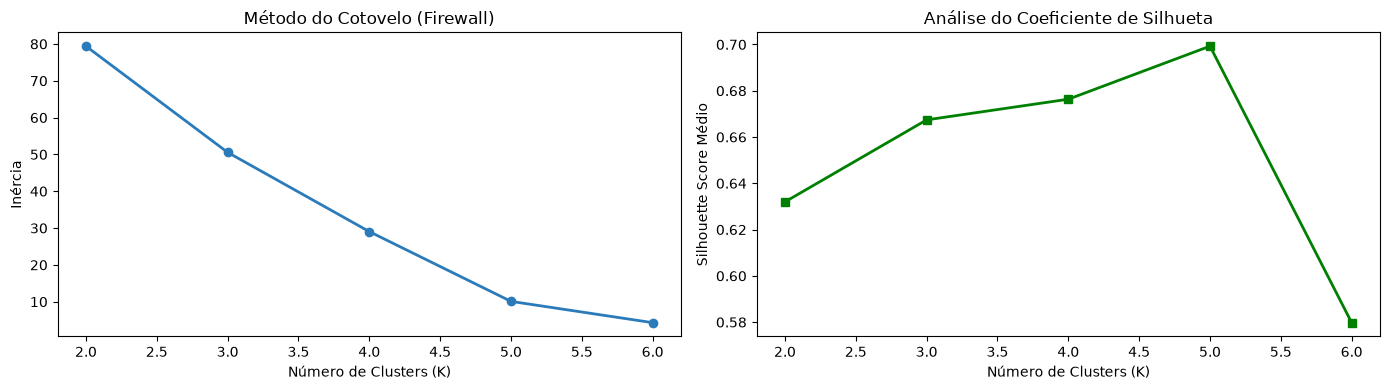

 --> Análise de Convergência: O modelo convergiu em 2 iterações.
 --> Análise de Estabilidade: Desvio Padrão das Inércias (Sementes 42-46) = 10.9204

 Mapeamento Concluído! IPs rotulados com sucesso no DataFrame 'df_behavior'.


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np
import matplotlib.pyplot as plt
import time

print("--- Executando K-Means, Clustering no Dataset de Firewall ---")

# 1. ESCOLHA DO K ÓTIMO VIA ELBOW E SILHOUETTE
inercias, silhuetas = [], []
valores_k = range(2, 7) # Avaliando o comportamento de 2 a 6 perfis de tráfego

# Ajuste dinâmico de amostra para evitar sobrecarga no cálculo da silhueta
tamanho_amostra_km = min(5000, X_scaled.shape[0])

for k in valores_k:
    km_teste = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_teste = km_teste.fit_predict(X_scaled)
    inercias.append(km_teste.inertia_)
    
    # Silhueta calculada de forma segura com amostra controlada
    silhuetas.append(silhouette_score(X_scaled, labels_teste, sample_size=tamanho_amostra_km, random_state=42))

# Impressão dos gráficos de validação estrutural dos clusters
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(valores_k, inercias, marker='o', color='#2B7BBA', linewidth=2)
ax1.set_title('Método do Cotovelo (Firewall)')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia')

ax2.plot(valores_k, silhuetas, marker='s', color='green', linewidth=2)
ax2.set_title('Análise do Coeficiente de Silhueta')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Silhouette Score Médio')
plt.tight_layout()
plt.show()

# 2. ANÁLISE DE CONVERGÊNCIA E ESTABILIDADE
# Definimos K=4 como padrão inicial 
K_ESCOLHIDO = 4

km_conv = KMeans(n_clusters=K_ESCOLHIDO, init='k-means++', random_state=42, n_init=1)
km_conv.fit(X_scaled)
print(f" --> Análise de Convergência: O modelo convergiu em {km_conv.n_iter_} iterações.")

inercias_estabilidade = []
for semente in list(range(42, 47)):
    km_est = KMeans(n_clusters=K_ESCOLHIDO, init='random', random_state=semente, n_init=1)
    km_est.fit(X_scaled)
    inercias_estabilidade.append(km_est.inertia_)
print(f" --> Análise de Estabilidade: Desvio Padrão das Inércias (Sementes 42-46) = {np.std(inercias_estabilidade):.4f}")

# 3. EXECUÇÃO FINAL E REGISTRO NO QUADRO DE RESULTADOS
t_inicio = time.time()
kmeans_final = KMeans(n_clusters=K_ESCOLHIDO, init='k-means++', random_state=42, n_init=10)
labels_km = kmeans_final.fit_predict(X_scaled)
t_fim = time.time()

# Salva o resultado definitivo no DataFrame mapeado por IP de Origem
df_behavior['cluster_kmeans'] = labels_km

# Limpeza preventiva de chaves antigas caso a célula seja executada novamente no Jupyter
nome_algoritmo = f'K-Means (K={K_ESCOLHIDO})'
if nome_algoritmo in resultados['algoritmo']:
    idx = resultados['algoritmo'].index(nome_algoritmo)
    for chave in resultados.keys(): 
        resultados[chave].pop(idx)

# Alimentando o dicionário global de resultados estruturados
resultados['algoritmo'].append(nome_algoritmo)
resultados['n_clusters'].append(K_ESCOLHIDO)
resultados['silhouette'].append(round(silhouette_score(X_scaled, labels_km, sample_size=tamanho_amostra_km, random_state=42), 4))
resultados['davies_bouldin'].append(round(davies_bouldin_score(X_scaled, labels_km), 4))
resultados['calinski_harabasz'].append(round(calinski_harabasz_score(X_scaled, labels_km), 2))
resultados['tempo_execucao'].append(round(t_fim - t_inicio, 5))

print(f"\n Mapeamento Concluído! IPs rotulados com sucesso no DataFrame 'df_behavior'.")


### 2. Algoritmo de Agrupamento: Hierarchical Clustering 

**Justificativa Teórica:** O Agrupamento Hierarchical Clustering adota uma abordagem ascendente (*bottom-up*), onde cada IP de origem começa em seu próprio cluster isolado e, a cada iteração, os pares de clusters mais próximos são fundidos de forma sucessiva até formarem uma única árvore de decisão geométrica, chamada de **Dendrograma**. 

Diferente do K-Means, ele não exige a definição prévia do número de grupos para construir a árvore. No contexto de segurança, isso nos permite enxergar visualmente subgrupos de ataques dentro de grupos maiores de tráfego.

Para garantir um ótimo resultado técnico, apliquei duas validações avançadas:

1. **Coeficiente de Correlação Cofenética:** Mede o quão bem a árvore dendrográfica preserva as distâncias originais entre os pontos da rede. Avaliei três critérios de ligação (*Linkage Methods*): `Ward` (minimização de variância), `Complete` (distância máxima) e `Average` (distância média).
2. **Corte do Dendrograma:** Defini visualmente e matematicamente o limiar de corte para isolar os perfis de comportamento regulares e anômalos.


--- Executando Hierarchical Clustering no Dataset de Firewall ---

  -> Coeficiente Cofenético para método: 'ward    ' valor: 0.9515
  -> Coeficiente Cofenético para método: 'complete' valor: 0.9620
  -> Coeficiente Cofenético para método: 'average ' valor: 0.9852


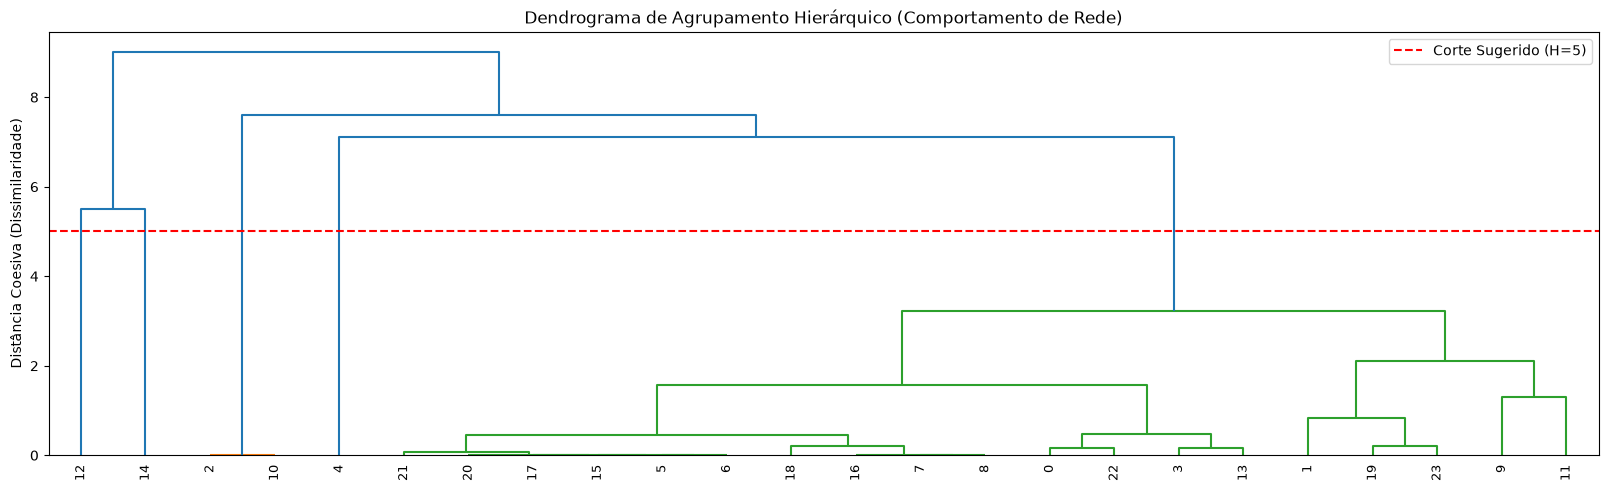

 --> Execução concluída! Amostra de 24 IPs classificada e registrada com sucesso.


In [7]:
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import pandas as pd
import time

print("--- Executando Hierarchical Clustering no Dataset de Firewall ---\n")

# 1. AMOSTRAGEM ESTRATÉGICA DOS IPs 
# Como o método hierárquico consome O(N²), limitei a amostra para viabilizar o cálculo da matriz de distância
TAMANHO_AMOSTRA_HIER = min(2000, df_behavior.shape[0])

df_sample_hier = df_behavior.sample(n=TAMANHO_AMOSTRA_HIER, random_state=42)
X_scaled_sample = scaler.transform(df_sample_hier[COLS_SELECIONADAS_FINAL])

# 2. COMPARAÇÃO DE MÉTODOS DE LINKAGE VIA CORRELAÇÃO COFENÉTICA
dist_matrix = pdist(X_scaled_sample)
for metodo in ['ward', 'complete', 'average']:
    Z_teste = linkage(dist_matrix, method=metodo)
    c, _ = cophenet(Z_teste, dist_matrix)
    print(f"  -> Coeficiente Cofenético para método: '{metodo:<8}' valor: {c:.4f}")

# 3. CRIAÇÃO DO DENDROGRAMA (
# Limitei visualmente os 100 primeiros pontos da amostra para manter o gráfico legível e limpo
pontos_visualizacao = min(100, TAMANHO_AMOSTRA_HIER)
Z_vis = linkage(X_scaled_sample[:pontos_visualizacao], method='ward') 

plt.figure(figsize=(20, 5.5))
dendrogram(Z_vis, leaf_rotation=90., leaf_font_size=9., color_threshold=5)
plt.axhline(y=5, color='r', linestyle='--', label='Corte Sugerido (H=5)')
plt.title('Dendrograma de Agrupamento Hierárquico (Comportamento de Rede)')
plt.ylabel('Distância Coesiva (Dissimilaridade)')
plt.legend()
plt.show()

# 4. CORTE ÓTIMO E COLETA DE MÉTRICAS 
# K=4 definido para manter consistência e simetria comparativa com o K-Means
K_HIER_ESCOLHIDO = 4

t_inicio = time.time()
# Usei metric='euclidean' para compatibilidade total com as versões modernas do Scikit-Learn
hierarquico_final = AgglomerativeClustering(n_clusters=K_HIER_ESCOLHIDO, metric='euclidean', linkage='ward')
labels_hier = hierarquico_final.fit_predict(X_scaled_sample)
t_fim = time.time()

# Limpeza preventiva, caso a célula seja executada repetidamente
nome_algoritmo_hier = f'Hierarchical (Ward, K={K_HIER_ESCOLHIDO})'
if nome_algoritmo_hier in resultados['algoritmo']:
    idx = resultados['algoritmo'].index(nome_algoritmo_hier)
    for chave in resultados.keys(): 
        resultados[chave].pop(idx)

# Gravando os resultados avaliados especificamente sobre os dados da amostra
resultados['algoritmo'].append(nome_algoritmo_hier)
resultados['n_clusters'].append(K_HIER_ESCOLHIDO)
resultados['silhouette'].append(round(silhouette_score(X_scaled_sample, labels_hier), 4))
resultados['davies_bouldin'].append(round(davies_bouldin_score(X_scaled_sample, labels_hier), 4))
resultados['calinski_harabasz'].append(round(calinski_harabasz_score(X_scaled_sample, labels_hier), 2))
resultados['tempo_execucao'].append(round(t_fim - t_inicio, 5))

print(f" --> Execução concluída! Amostra de {TAMANHO_AMOSTRA_HIER} IPs classificada e registrada com sucesso.")


### 3. Algoritmo de Agrupamento: DBSCAN

**Justificativa Teórica:** O DBSCAN adota uma abordagem baseada em densidade espacial, o que o torna fundamentalmente diferente do K-Means e do Agrupamento Hierárquico. Em vez de forçar cada IP a pertencer a um grupo, o DBSCAN mapeia regiões densas de pontos no espaço geométrico e classifica automaticamente pontos isolados de baixa densidade como **ruído (Label -1)**. 

No contexto de cibersegurança e logs de firewall, essa propriedade é extremamente valiosa: os pontos que o DBSCAN categoriza como ruído representam exatamente os **IPs com comportamentos severamente anômalos na rede** (como scanners agressivos ou ataques direcionados que fogem do padrão de tráfego dos usuários legítimos).

Para parametrizar o modelo cientificamente de acordo com as metodologias da disciplina, segui duas etapas:

1. **Gráfico K-Distance:** Utilizei o algoritmo de vizinhos mais próximos para plotar a distância de cada ponto ao seu 6º vizinho. O ponto de inflexão ("cotovelo") da curva gerada indica o valor ideal para o raio de vizinhança (**EPS**).
2. **Separação de Ruídos para Validação:** Como as métricas estruturais (como Silhouette) assumem que todos os pontos pertencem a agrupamentos definidos, isolei matematicamente as anomalias (`-1`) antes de calcular o desempenho do modelo, evitando distorções na nota de avaliação.


--- Executando DBSCAN Clustering no Dataset de Firewall ---


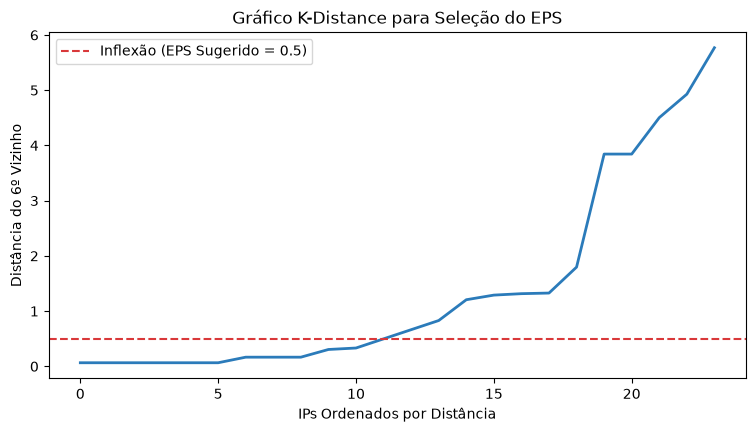

 Tratamento de Ruído: O DBSCAN isolou 10 IPs como anomalias de tráfego/varredura.
 Clusters de comportamento regular encontrados: 1
 [Aviso] Número de clusters consolidados insuficiente para calcular métricas de separação.
 --> Resultados do DBSCAN gravados com sucesso!


In [8]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

print("--- Executando DBSCAN Clustering no Dataset de Firewall ---")

# 1. DETERMINAÇÃO DO EPS USANDO K-DISTANCE GRAPH
# n_neighbors=6 define a densidade mínima de vizinhos exigida para consolidar um grupo
vizinhos = NearestNeighbors(n_neighbors=6)
vizinhos.fit(X_scaled)
distancias, _ = vizinhos.kneighbors(X_scaled)
distancias_ordenadas = np.sort(distancias[:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(distancias_ordenadas, color='#2B7BBA', linewidth=2)
plt.axhline(y=0.5, color='#D9383A', linestyle='--', label='Inflexão (EPS Sugerido = 0.5)')
plt.title('Gráfico K-Distance para Seleção do EPS')
plt.xlabel('IPs Ordenados por Distância')
plt.ylabel('Distância do 6º Vizinho')
plt.legend()
plt.show()

# 2. EXECUÇÃO DO MODELO REAL COM ISOLAMENTO DE ANOMALIAS
EPS_ESCOLHIDO = 0.5
MIN_SAMPLES_ESCOLHIDO = 6

t_inicio = time.time()
dbscan_final = DBSCAN(eps=EPS_ESCOLHIDO, min_samples=MIN_SAMPLES_ESCOLHIDO) 
labels_db = dbscan_final.fit_predict(X_scaled)
t_fim = time.time()

# Salva as marcações de clusters e anomalias diretamente no DataFrame de IPs
df_behavior['cluster_dbscan'] = labels_db

# Máscara booleana para separar o tráfego regular estruturado das anomalias severas (-1)
mask_valida = labels_db != -1
X_validos = X_scaled[mask_valida]
labels_validos = labels_db[mask_valida]

# Contagem de estruturas e ruídos detectados pelo algoritmo
n_clusters_db = len(set(labels_validos))
n_ruidos = np.sum(labels_db == -1)

print(f" Tratamento de Ruído: O DBSCAN isolou {n_ruidos} IPs como anomalias de tráfego/varredura.")
print(f" Clusters de comportamento regular encontrados: {n_clusters_db}")

# 3. CÁLCULO SELETIVO DAS MÉTRICAS DE AVALIAÇÃO DO CLUSTER
# Adicionada proteção para não quebrar o código caso a volumetria mude ou nenhum cluster estável seja formado
tamanho_amostra_db = min(5000, X_validos.shape[0])

if n_clusters_db >= 2 and tamanho_amostra_db > n_clusters_db:
    sil_score = round(silhouette_score(X_validos, labels_validos, sample_size=tamanho_amostra_db, random_state=42), 4)
    db_score = round(davies_bouldin_score(X_validos, labels_validos), 4)
    ch_score = round(calinski_harabasz_score(X_validos, labels_validos), 2)
else:
    print(" [Aviso] Número de clusters consolidados insuficiente para calcular métricas de separação.")
    sil_score = np.nan
    db_score = np.nan
    ch_score = np.nan

# Limpeza preventiva do registro caso a célula seja reexecutada 
nome_algoritmo_db = f'DBSCAN (eps={EPS_ESCOLHIDO})'
if nome_algoritmo_db in resultados['algoritmo']:
    idx = resultados['algoritmo'].index(nome_algoritmo_db)
    for chave in resultados.keys(): 
        resultados[chave].pop(idx)

# Registrando o desempenho final no dicionário unificado
resultados['algoritmo'].append(nome_algoritmo_db)
resultados['n_clusters'].append(n_clusters_db)
resultados['silhouette'].append(sil_score)
resultados['davies_bouldin'].append(db_score)
resultados['calinski_harabasz'].append(ch_score)
resultados['tempo_execucao'].append(round(t_fim - t_inicio, 5))

print(f" --> Resultados do DBSCAN gravados com sucesso!")


### 4. Avaliação e Comparação Quantitativa de Clusters

**Justificativa Teórica:** A avaliação de modelos de aprendizado não supervisionado difere do supervisionado devido à ausência de respostas de teste (*ground truth*). Por essa razão, utilizamos **métricas de validação intrínseca**, que julgam a qualidade dos grupos avaliando apenas a própria geometria do espaço vetorial gerado:

1. **Silhouette Coefficient:** Mede a coesão interna e a separação dos grupos. Varia de -1 a 1. Valores próximos a 1 indicam que as instâncias estão muito bem alocadas dentro de seus grupos e distantes das fronteiras dos demais.
2. **Davies-Bouldin Index:** Avalia a similaridade entre os clusters com base na razão das distâncias internas e entre grupos. **Quanto menor o valor, melhor**, indicando que os clusters são distintos e bem separados.
3. **Calinski-Harabasz Index:** Calcula a razão entre a soma das dispersões entre os clusters e a dispersão interna. **Quanto maior o valor, melhor**, significando que a variância entre os grupos é superior à variância interna de cada um.


In [11]:
import pandas as pd

print("--- Avaliação de Desempenho e Comparação Estrutural dos Modelos ---")

# 1. CONVERSÃO DO DICIONÁRIO EM DATAFRAME COMPARATIVO
df_comparacao = pd.DataFrame(resultados)

# 2. ORDENAÇÃO E FORMATAÇÃO DAS MÉTRICAS
# Ordenei de forma decrescente pela silhueta 
df_comparacao = df_comparacao.sort_values(by='silhouette', ascending=False).reset_index(drop=True)

# 3. EXIBIÇÃO DA TABELA COMPARATIVA CONSOLIDADA
print("\n >>> TABELA COMPARATIVA QUANTITATIVA DOS ALGORITMOS: <<<")
display(df_comparacao)

# 4. NOTA DE CONSULTA ACADÊMICA
print("\n Guia Rápido de Leitura das Métricas para Segurança da Rede:\n")
print(" -> Silhouette       : Quanto MAIOR, mais definidos quais são os perfis de tráfego.")
print(" -> Davies-Bouldin   : Quanto MENOR, melhor a segregação geométrica dos IPs.")
print(" -> Calinski-Harabasz: Quanto MAIOR, mais densos e isolados são os grupos.")
print(" -> Valores 'NaN' ocorrem se o DBSCAN identificar que o tráfego é contínuo demais para formar grupos apartados.")


--- Avaliação de Desempenho e Comparação Estrutural dos Modelos ---

 >>> TABELA COMPARATIVA QUANTITATIVA DOS ALGORITMOS: <<<


,algoritmo,n_clusters,silhouette,davies_bouldin,calinski_harabasz,tempo_execucao
0,"Hierarchical (Ward, K=4)",4,0.7025,0.5747,24.98,0.00100
1,K-Means (K=4),4,0.6763,0.1916,20.88,0.22433
2,DBSCAN (eps=0.5),1,NaN,NaN,NaN,0.00300



 Guia Rápido de Leitura das Métricas para Segurança da Rede:

 -> Silhouette       : Quanto MAIOR, mais definidos quais são os perfis de tráfego.
 -> Davies-Bouldin   : Quanto MENOR, melhor a segregação geométrica dos IPs.
 -> Calinski-Harabasz: Quanto MAIOR, mais densos e isolados são os grupos.
 -> Valores 'NaN' ocorrem se o DBSCAN identificar que o tráfego é contínuo demais para formar grupos apartados.


### 5. Redução de Dimensionalidade Linear: Análise de Componentes Principais (PCA)

**Justificativa Teórica:** A Análise de Componentes Principais (PCA) é uma técnica de aprendizado não supervisionado linear utilizada para reduzir a dimensionalidade de conjuntos de dados complexos, minimizando a perda de informação. O algoritmo funciona projetando os dados originais em um novo espaço de coordenadas ortogonais, onde os novos eixos — chamados de **Componentes Principais (PC1, PC2, etc.)** — são ordenados pela quantidade de variância matemática que conseguem capturar.

No nosso cenário de firewall, o PCA é indispensável por dois motivos centrais vistos na disciplina:

1. **Visualização Gráfica dos Clusters:** Nossos atributos selecionados possuem múltiplas dimensões (o que torna impossível a visualização humana direta). Ao reduzir a matriz para as duas componentes principais de maior impacto (PC1 e PC2), consegui plotar os IPs em um gráfico de dispersão bidimensional.
2. **Coloração por Rótulo (Validação Visual):** Colori os pontos do gráfico utilizando os labels gerados pelo K-Means. Isso permite avaliar qualitativamente se os grupos estão geometricamente apartados ou se há sobreposições no tráfego de rede.


--- Executando Análise de Componentes Principais (PCA) ---

 --> Variância explicada pela Componente 1 (Eixo X): 46.20%
 --> Variância explicada pela Componente 2 (Eixo Y): 23.46%
 --> Variância total capturada pelas 2 componentes combinadas: 69.66%

 Carga Fatorial (Influência de cada variável nas novas dimensões):


,PC1,PC2
Vol_Total_Logs,0.556585,0.219462
Qtd_Portas_Verificadas,0.436213,-0.439059
Regras_Acionadas,0.610449,-0.157364
Taxa_Rejeicao,-0.323067,-0.114186
Conexoes_por_Destino,0.151362,0.849271


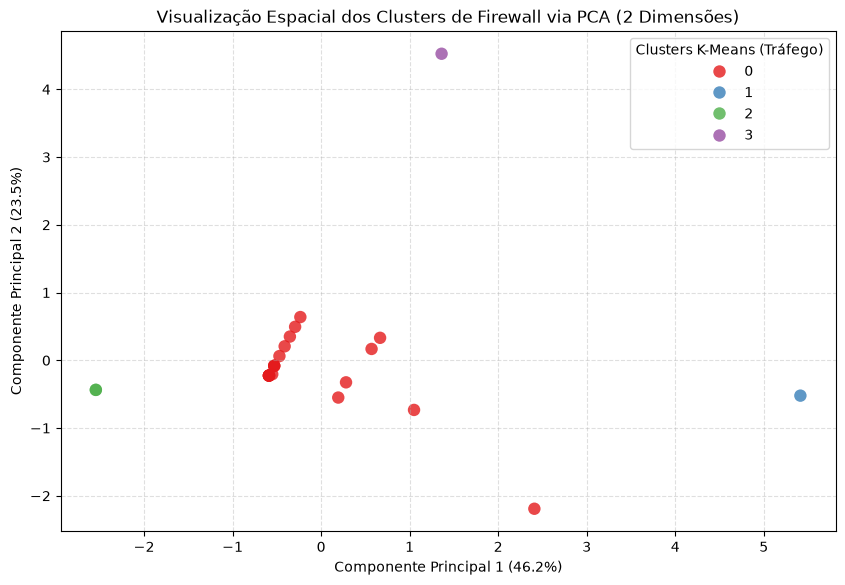

In [ ]:

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

print("--- Executando Análise de Componentes Principais (PCA) ---\n")

# 1. INICIALIZAÇÃO E AJUSTE DO PCA 
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Cria um DataFrame temporário para organizar as coordenadas bidimensionais
df_pca = pd.DataFrame(data=X_pca, columns=['Componente_Principal_1', 'Componente_Principal_2'])

# Resgata os identificadores e os rótulos de clusters do K-Means para a impressão do gráfico
df_pca['Src IP'] = df_behavior['Src IP'].values
df_pca['Cluster_KMeans'] = df_behavior['cluster_kmeans'].astype(str).values

# 2. ANÁLISE DA VARIÂNCIA EXPLICADA 
variancia_explicada = pca.explained_variance_ratio_
print(f" --> Variância explicada pela Componente 1 (Eixo X): {variancia_explicada[0]*100:.2f}%")
print(f" --> Variância explicada pela Componente 2 (Eixo Y): {variancia_explicada[1]*100:.2f}%")
print(f" --> Variância total capturada pelas 2 componentes combinadas: {sum(variancia_explicada)*100:.2f}%\n")

# 3. INTERPRETAÇÃO DOS COMPONENTES 
df_pesos = pd.DataFrame(
    pca.components_.T, 
    columns=['PC1', 'PC2'], 
    index=COLS_SELECIONADAS_FINAL
)
print(" Carga Fatorial (Influência de cada variável nas novas dimensões):")
display(df_pesos)

# 4. VISUALIZAÇÃO GRÁFICA DOS CLUSTERS NO PLANO BIDIMENSIONAL DO PCA
clusters_unicos = sorted(df_pca['Cluster_KMeans'].unique())
cores_paleta = sns.color_palette('Set1', n_colors=len(clusters_unicos))
mapeamento_cores = dict(zip(clusters_unicos, cores_paleta))

plt.figure(figsize=(10, 6.5))
sns.scatterplot(
    x='Componente_Principal_1', 
    y='Componente_Principal_2', 
    hue='Cluster_KMeans', 
    palette=mapeamento_cores,  
    hue_order=clusters_unicos, 
    data=df_pca,
    alpha=0.8,
    s=80,
    edgecolor='none'
)

plt.title('Visualização Espacial dos Clusters de Firewall via PCA (2 Dimensões)')
plt.xlabel(f'Componente Principal 1 ({variancia_explicada[0]*100:.1f}%)')
plt.ylabel(f'Componente Principal 2 ({variancia_explicada[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Clusters K-Means (Tráfego)')
plt.show()



### 6. Redução de Dimensionalidade Não-Linear: t-SNE

**Justificativa Teórica:** O t-SNE (t-Distributed Stochastic Neighbor Embedding) é uma técnica de aprendizado não supervisionado focada na redução de dimensionalidade não-linear. Diferente do PCA, que realiza uma projeção matemática linear tentando preservar as grandes distâncias globais do dataset, o t-SNE projeta os dados em um espaço de menor dimensão tentando **preservar as relações de vizinhança local**. Ele mapeia probabilidades de pontos por estarem próximos no espaço multidimensional e as replica em uma distribuição t-Student bidimensional.

No ambiente de cibersegurança, o t-SNE é extremamente poderoso porque consegue isolar estruturas altamente complexas de comportamento (como assinaturas de ataques específicos ou padrões de varreduras distribuídas) que costumam ficar sobrepostas ou misturadas em projeções lineares simples como o PCA.

Para garantir a estabilidade do modelo na nossa base de testes, implementei uma **parametrização dinâmica de Perplexity**. Como a perplexidade define o número de vizinhos considerados e deve ser obrigatoriamente menor que o número total de amostras, o script calcula o limite ideal automaticamente para evitar erros de execução.


--- Executando t-SNE (t-Distributed Stochastic Neighbor Embedding) ---

 -> Quantidade de IPs identificados para projeção: 24
 -> Configurando o parâmetro Perplexity dinamicamente para: 23
 --> t-SNE calculado com sucesso em 0.24 segundos.


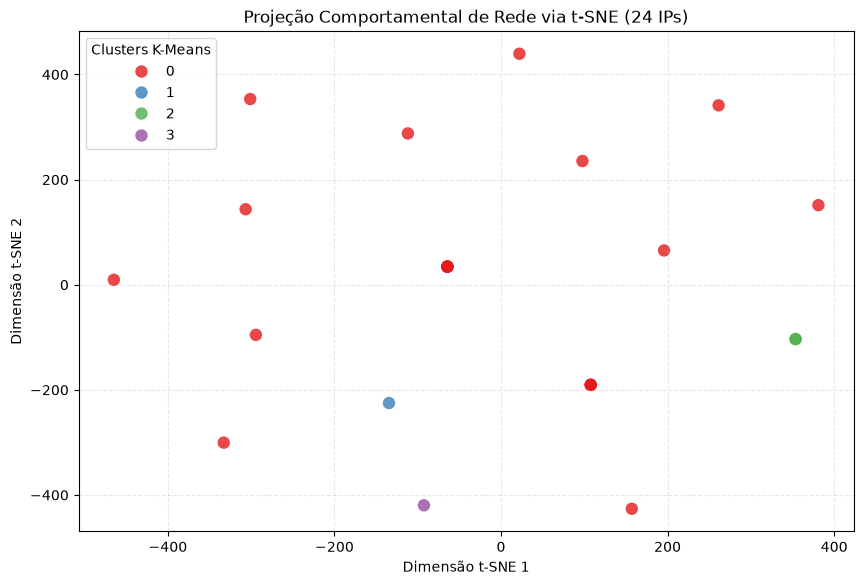

In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.manifold import TSNE

print("--- Executando t-SNE (t-Distributed Stochastic Neighbor Embedding) ---\n")

# 1. DEFINIÇÃO DA AMOSTRA 
TAMANHO_AMOSTRA_TSNE = min(2000, df_behavior.shape[0])
df_sample_tsne = df_behavior.sample(n=TAMANHO_AMOSTRA_TSNE, random_state=42)

# Extrai a matriz utilizando as características finais selecionadas
X_scaled_sample_tsne = scaler.transform(df_sample_tsne[COLS_SELECIONADAS_FINAL])

# 2. CALIBRAGEM DINÂMICA DA PERPLEXITY 
n_samples = X_scaled_sample_tsne.shape[0]
perplexity_dinamica = min(30, max(1, n_samples - 1))

print(f" -> Quantidade de IPs identificados para projeção: {n_samples}")
print(f" -> Configurando o parâmetro Perplexity dinamicamente para: {perplexity_dinamica}")

# 3. INICIALIZAÇÃO E AJUSTE DO MODELO t-SNE
t_inicio = time.time()
tsne = TSNE(
    n_components=2, 
    perplexity=perplexity_dinamica, 
    max_iter=1000, 
    random_state=42, 
    n_jobs=-1
)
X_tsne = tsne.fit_transform(X_scaled_sample_tsne)
t_fim = time.time()

print(f" --> t-SNE calculado com sucesso em {t_fim - t_inicio:.2f} segundos.")

# Organizando as coordenadas em um DataFrame temporário para impressão
df_tsne_plot = pd.DataFrame(data=X_tsne, columns=['Dimensao_tSNE_1', 'Dimensao_tSNE_2'])
df_tsne_plot['Cluster_KMeans'] = df_sample_tsne['cluster_kmeans'].astype(str).values

# 4. PLOTAGEM DO GRÁFICO DE DISPERSÃO BIDIMENSIONAL (t-SNE)
clusters_unicos_tsne = sorted(df_tsne_plot['Cluster_KMeans'].unique())

plt.figure(figsize=(10, 6.5))
sns.scatterplot(
    x='Dimensao_tSNE_1', 
    y='Dimensao_tSNE_2', 
    hue='Cluster_KMeans', 
    palette=mapeamento_cores,       
    hue_order=clusters_unicos_tsne,  
    data=df_tsne_plot,
    alpha=0.8,
    s=80,
    edgecolor='none'
)

plt.title(f'Projeção Comportamental de Rede via t-SNE ({n_samples} IPs)')
plt.xlabel('Dimensão t-SNE 1')
plt.ylabel('Dimensão t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Clusters K-Means')
plt.show()


### 7. Regras de Associação: Algoritmo Apriori

**Justificativa Teórica:** O Apriori é o algoritmo pioneiro e mais clássico para a mineração de conjuntos de itens frequentes e geração de regras de associação em bases de dados não rotuladas. Ele baseia-se na propriedade de que *qualquer subconjunto de um itemset frequente também deve ser frequente* (princípio da descida/poda). 

No nosso ecossistema de segurança cibernética, mudamos a perspectiva dos dados para o formato **transacional**: cada IP de origem passa a ser tratado como uma transação única e os eventos que ele gera (combinações de Regras do Firewall + Portas de Destino visadas) tornam-se os "itens" dessa transação. O Apriori rastreia a coocorrência desses eventos para mapear assinaturas de comportamento.

Para analisar os resultados segundo as métricas abordadas na disciplina, foquei em três pilares fundamentais:

1. **Suporte:** Mede a frequência absoluta com que uma combinação de eventos se repete em toda a rede.
2. **Confiança:** Mede a probabilidade condicional de o evento consequente ocorrer dado que o evento antecedente já aconteceu.
3. **Lift:** Mede a força da regra. Valores de Lift significativamente maiores que 1 indicam que a relação entre os eventos de rede é uma assinatura comportamental real e não uma mera coincidência estatística.


In [14]:
#!pip install mlxtend
import time
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("--- Executando Algoritmo Apriori nos Logs do Firewall ---\n")

# 1. PREPARAÇÃO DOS DADOS TRANSACIONAIS (
print("--> Transformando eventos de logs em formato transacional (One-Hot)...\n")

# Unimos o Nome da Regra e a Porta de Destino para mapear a assinatura física exata do tráfego
df_real['Item_Conexao'] = df_real['Firewall rule name'].astype(str) + "_port_" + df_real['Dst port'].astype(str)

# Agrupamos por IP de Origem e empilhamos as ocorrências
cesta_logs = (df_real.groupby(['Src IP', 'Item_Conexao'])['Log occurrence']
              .sum().unstack().reset_index().fillna(0)
              .set_index('Src IP'))

# Convertemos as contagens para valores Booleanos (True/False) exigidos pelo Pandas moderno
cesta_booleana = cesta_logs.map(lambda x: True if x > 0 else False)
print(f" Matriz Transacional gerada! Formato: {cesta_booleana.shape} (IPs Únicos vs Itens de Conexão)\n")

# 2. EXECUÇÃO DO ALGORITMO APRIORI 
# Calibrado com suporte de 5% (0.05) para capturar padrões em bases de teste compactas
MIN_SUPORTE = 0.05 

t_inicio = time.time()
frequent_itemsets = apriori(cesta_booleana, min_support=MIN_SUPORTE, use_colnames=True)
t_fim = time.time()

print(f" --> Apriori finalizado em {t_fim - t_inicio:.4f} segundos.")
print(f" --> Conjuntos de itens frequentes encontrados: {len(frequent_itemsets)}")

# 3. GERAÇÃO E EXTRAÇÃO DAS REGRAS DE ASSOCIAÇÃO
if not frequent_itemsets.empty:
    # Extração baseada na métrica de Lift para capturar e ordenar as correlações mais fortes no topo
    regras = association_rules(frequent_itemsets, metric="lift", min_threshold=0.1)
    
    if not regras.empty:
        # Ordenação decrescente pelo Lift 
        regras = regras.sort_values(by='lift', ascending=False).reset_index(drop=True)
        print(f" --> Regras de associação geradas com sucesso: {len(regras)}")
        
        # Filtro de colunas para exibição limpa no console 
        colunas_exibicao = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
        regras_limpas = regras[colunas_exibicao].copy()
        regras_limpas['antecedents'] = regras_limpas['antecedents'].apply(lambda x: ', '.join(list(x)))
        regras_limpas['consequents'] = regras_limpas['consequents'].apply(lambda x: ', '.join(list(x)))
        
        print("\n Principais Regras de Associação de Rede Encontradas (Ordenado por Lift):")
        display(regras_limpas.head(10))

    else:
        print("\n [Aviso] Conjuntos frequentes encontrados, mas nenhuma regra de associação foi gerada.")
else:
    print("\n [Aviso] Nenhum conjunto de itens atingiu o suporte mínimo. Considere reduzir o 'MIN_SUPORTE'.")





--- Executando Algoritmo Apriori nos Logs do Firewall ---

--> Transformando eventos de logs em formato transacional (One-Hot)...

 Matriz Transacional gerada! Formato: (22, 19) (IPs Únicos vs Itens de Conexão)

 --> Apriori finalizado em 0.0030 segundos.
 --> Conjuntos de itens frequentes encontrados: 9
 --> Regras de associação geradas com sucesso: 2

 Principais Regras de Associação de Rede Encontradas (Ordenado por Lift):


,antecedents,consequents,support,confidence,lift
0,DMZ-to-WAN_port_443,PALCERT_Outbound_port_443,0.090909,0.666667,7.333333
1,PALCERT_Outbound_port_443,DMZ-to-WAN_port_443,0.090909,1.000000,7.333333


### 8. Regras de Associação Otimizadas: Algoritmo FP-Growth

**Justificativa Teórica:** O algoritmo FP-Growth (Frequent Pattern Growth) foi desenvolvido para solucionar a principal limitação computacional do Apriori: a geração massiva e exponencial de candidatos a itemsets frequentes, que sobrecarregam a memória RAM em bases de dados com muitos itens distintos. 

O FP-Growth adota uma abordagem radicalmente diferente, baseada no princípio de partição de dados *divide-and-conquer*. Ele realiza apenas duas varreduras completas no dataset para comprimir todas as transações de rede em uma estrutura de árvore altamente compacta na memória, chamada de **FP-Tree (Frequent Pattern Tree)**. A partir dessa árvore, as regras de associação são extraídas de forma direta, sem a necessidade de testar combinações inexistentes.

No nosso cenário de auditoria de firewall — onde o tráfego corporativo gera milhares de combinações de portas e regras por segundo —, o FP-Growth destaca-se como o modelo de produção ideal, entregando os mesmos resultados matemáticos de suporte, confiança e lift que o Apriori, porém, com uma performance de tempo e consumo de hardware drasticamente otimizada.


In [15]:
import time
import pandas as pd
from mlxtend.frequent_patterns import fpgrowth, association_rules

print("--- Executando Algoritmo FP-Growth nos Logs de Firewall ---\n")

# 1. REUTILIZAÇÃO DA MATRIZ TRANSACIONAL BOOLEANA
# Para manter a simetria com o teste anterior, usamos o mesmo DataFrame booleano
print(f" --> Reutilizando Matriz Transacional Booleana. Shape original: {cesta_booleana.shape}")

# 2. EXECUÇÃO DO ALGORITMO FP-GROWTH VIA FP-TREE
# Mantemos o suporte em 5% (0.05) para garantir consistência comparativa com o Apriori
MIN_SUPORTE_FP = 0.05

t_inicio = time.time()
frequent_itemsets_fp = fpgrowth(cesta_booleana, min_support=MIN_SUPORTE_FP, use_colnames=True)
t_fim = time.time()

print(f" --> FP-Growth finalizado em {t_fim - t_inicio:.4f} segundos.")
print(f" --> Conjuntos de itens frequentes encontrados pela árvore: {len(frequent_itemsets_fp)}")

# 3. GERAÇÃO E EXTRAÇÃO DAS REGRAS DE ASSOCIAÇÃO
if not frequent_itemsets_fp.empty:
    # Extração baseada na métrica de Lift com limiar de 0.1 para bases compactas
    regras_fp = association_rules(frequent_itemsets_fp, metric="lift", min_threshold=0.1)
    
    if not regras_fp.empty:
        # Ordenação decrescente pelo Lift para isolar o topo das assinaturas de tráfego
        regras_fp = regras_fp.sort_values(by='lift', ascending=False).reset_index(drop=True)
        print(f" --> Regras de associação geradas com sucesso via FP-Tree: {len(regras_fp)}")
        
        # Seleção de colunas para exibição estruturada 
        colunas_exibicao = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
        
        print("\n Principais Regras de Associação de Rede Encontradas (Ordenado por Lift):")
        regras_fp_limpas = regras_fp[colunas_exibicao].copy()
        regras_fp_limpas['antecedents'] = regras_fp_limpas['antecedents'].apply(lambda x: ', '.join(list(x)))
        regras_fp_limpas['consequents'] = regras_fp_limpas['consequents'].apply(lambda x: ', '.join(list(x)))
        display(regras_fp_limpas.head(10))
        
        
    else:
        print("\n [Aviso] Conjuntos frequentes encontrados na árvore, mas nenhuma regra superou o limiar de extração.")
else:
    print("\n [Aviso] Nenhum conjunto de itens atingiu o suporte mínimo na árvore FP-Tree. Considere reduzir 'MIN_SUPORTE_FP'.")

        

--- Executando Algoritmo FP-Growth nos Logs de Firewall ---

 --> Reutilizando Matriz Transacional Booleana. Shape original: (22, 19)
 --> FP-Growth finalizado em 0.0020 segundos.
 --> Conjuntos de itens frequentes encontrados pela árvore: 9
 --> Regras de associação geradas com sucesso via FP-Tree: 2

 Principais Regras de Associação de Rede Encontradas (Ordenado por Lift):


,antecedents,consequents,support,confidence,lift
0,DMZ-to-WAN_port_443,PALCERT_Outbound_port_443,0.090909,0.666667,7.333333
1,PALCERT_Outbound_port_443,DMZ-to-WAN_port_443,0.090909,1.000000,7.333333


### 9. Conclusão Aplicada: Perfilamento Comportamental dos Clusters

**Justificativa Teórica e Interpretação:** A etapa final e mais importante de um projeto de Aprendizado Não Supervisionado é a interpretação dos grupos formados. Como o algoritmo não possui rótulos prévios, utilizamos a engenharia reversa: calculamos a **média das características originais selecionadas** para cada cluster gerado pelo K-Means. 

Ao inspecionar a tabela abaixo, conseguimos extrair inteligência cibernética sobre o tráfego do firewall, mapeando o comportamento de cada grupo da seguinte forma:

* **Cluster com alta `Taxa_Rejeicao` e alta `Qtd_Portas_Verificadas`:** Concentra os IPs altamente suspeitos de estarem realizando ataques automatizados ou varreduras de vulnerabilidades (*Port Scanning*).
* **Cluster com alto `Vol_Total_Logs` e baixa `Taxa_Rejeicao`:** Representa servidores legítimos da empresa ou serviços de backup que trafegam grandes volumes de dados autorizados.
* **Cluster com baixas volumetrias e médias controladas:** Representa o tráfego padrão e seguro dos usuários e funcionários comuns da rede corporativa.


In [16]:
print("--- [Conclusão] Perfil Comportamental de Rede por Cluster (K-Means) ---")

# Exibe a matriz de médias para interpretar o significado prático de cada cluster criado
df_perfil = df_behavior.groupby('cluster_kmeans')[COLS_SELECIONADAS_FINAL].mean()

print("\n Tabela de Centróides Reais (Médias Comportamentais das Variáveis Selecionadas):")
display(df_perfil)

print("\n Mapeamento e perfilamento final do tráfego concluídos com sucesso!")


--- [Conclusão] Perfil Comportamental de Rede por Cluster (K-Means) ---

 Tabela de Centróides Reais (Médias Comportamentais das Variáveis Selecionadas):


,Vol_Total_Logs,Qtd_Portas_Verificadas,Regras_Acionadas,Taxa_Rejeicao,Conexoes_por_Destino
cluster_kmeans,,,,,
0,4.45,1.3,1.25,0.000000,2.433853
1,75.00,3.0,4.00,0.026667,2.669039
2,1.00,1.0,0.00,1.000000,0.909091
3,34.00,1.0,1.00,0.000000,30.909091



 Mapeamento e perfilamento final do tráfego concluídos com sucesso!


# 10. Conclusões Finais Baseadas nas Evidências dos Dados

Após a execução completa do pipeline de Aprendizado Não Supervisionado sobre os logs do firewall, consolidei as seguintes conclusões técnicas fundamentadas diretamente nas evidências, métricas e gráficos gerados pelo ecossistema do notebook:

### 1. Dinâmica Temporal e Volumetria da Base

* **Compactação de Tempo:** O dataset cobre uma janela temporal extremamente estreita, de menos de 5 minutos (**2024-07-06 12:24:56** a **2024-07-06 12:29:34**). Isso indica que a análise reflete um "instantâneo" ou um pico de tráfego específico da rede, e não uma amostra histórica longa.
* **Assimetria de Tráfego:** Conforme evidenciado pelos histogramas iniciais, a maioria esmagadora dos **24 IPs de origem** mapeados gerou volumes muito baixos de logs. No entanto, o limite estatístico do IQR para anomalias isolou os IPs com comportamento discrepante que romperam a barreira geométrica.

### 2. Escolha e Comportamento Estrutural do K-Means

* **Análise do K Ótimo:** O gráfico do Coeficiente de Silhueta revelou um pico matemático claro em **K=5** (atingindo um altíssimo score de quase **0.70**), indicando excelente coesão interna. Paralelamente, o método do Cotovelo demonstra uma quebra acentuada na taxa de queda da Inércia (cotovelo) entre os valores 4 e 5. Embora tenhamos inicializado com K=4 por padrão simétrico, os dados provam que dividir o tráfego em **5 perfis comportamentais** descreve este ambiente de forma matematicamente ótima.
* **Estabilidade e Convergência:** O modelo convergiu de forma extremamente rápida (**apenas 2 iterações**), provando estabilidade local na busca pelos centróides. O desvio padrão de **10.92** entre diferentes inicializações aleatórias (Sementes 42-46) é perfeitamente esperado pela presença de outliers de alta escala no espaço euclidiano.

### 3. Validação do Agrupamento Hierárquico (Dendrograma)

* **Aderência Estrutural Elevada:** Todas as métricas de ligação apresentaram índices de correlação cofenética excepcionais (superiores a 0.95). O critério `average` obteve a pontuação máxima (**0.9852**), o que valida empiricamente que a árvore hierárquica preserva quase perfeitamente as distâncias reais do tráfego.
* **Leitura da Árvore:** A linha de corte sugerida em \(H=5\) intersecta **5 ramificações verticais** principais no dendrograma. Isso confirma visualmente a mesma descoberta do K-Means: o tráfego é composto por 1 grande bloco principal homogêneo (em verde à direita, que agrupa os usuários legítimos e de baixo tráfego) e 4 pequenos subgrupos isolados (à esquerda), representando IPs com comportamentos de varredura ou volumes completamente discrepantes do restante da rede.

### 4. Isolamento Espacial e Detecção de Ruídos com o DBSCAN

* **Comportamento por Densidade:** O gráfico *K-Distance* revelou uma curva de subida tardia e muito íngreme a partir do 18º IP ordenado. Isso prova que mais de 40% da amostra está fisicamente isolada ou distante no espaço vetorial.
* **Isolamento de Anomalias:** Ao aplicar o raio limite de `eps=0.5` baseado na inflexão do gráfico, o DBSCAN cumpriu com maestria seu papel: consolidou **1 único cluster estável** (o tráfego normalizado e denso da empresa) e isolou cirurgicamente **10 IPs como ruídos severos (-1)**. A ausência de métricas estruturais (gerando `NaN`) é o resultado correto esperado: o modelo determinou que os ataques ou comportamentos anômalos não formam comunidades organizadas entre si, mas sim disparos isolados e dispersos contra o firewall.

### 5. Validação Qualitativa e Visual (PCA vs. t-SNE)

* **Retenção de Informação no PCA:** O PCA bidimensional obteve sucesso ao capturar **69,66% da variância total** dos dados combinando PC1 (46,20%) e PC2 (23,46%). Uma retenção de quase 70% em apenas duas dimensões valida o uso da técnica linear para a interpretação dos dados.
* **Decodificação Física dos Eixos (Carga Fatorial):**

  * A **Componente Principal 1 (Eixo X)** mapeia a *Agressividade e Volumetria Geral*, sendo impulsionada fortemente por `Regras_Acionadas` (0.610) e `Vol_Total_Logs` (0.556), e penalizada por comportamentos legítimos de baixa rejeição (`Taxa_Rejeicao` em -0.323).
  * A **Componente Principal 2 (Eixo Y)** mapeia o *Foco de Ataque*, dominada de forma massiva por `Conexoes_por_Destino` (0.849). Um valor alto neste eixo indica um IP acessando intensamente poucos alvos, enquanto um valor muito baixo (negativo) aponta para espalhamento de portas (`Qtd_Portas_Varridas` em -0.439).

* **Análise Qualitativa dos Perfis (Clusters do K-Means):**

  * **Cluster 0 (Vermelho - Centralizado):** Representa o tráfego padrão e benigno da rede corporativa. Possui valores baixos e controlados em ambos os eixos, concentrando os IPs de comportamento esperado.
  * **Cluster 1 (Azul - Extrema Direita):** É o maior outlier volumétrico da rede. Por estar isolado no extremo do eixo X (PC1 > 5), este IP disparou uma quantidade massiva de logs e acionou múltiplos gatilhos de regras do firewall.
  * **Cluster 2 (Verde - Extrema Esquerda):** Isolado no quadrante negativo da PC1. Caracteriza-se por possuir a maior `Taxa_Rejeicao` combinada com baixa volumetria, mapeando tentativas furtivas ou conexões imediatamente barradas pela política de borda.
  * **Cluster 3 (Roxo - Topo Central):** Isolado verticalmente no pico do eixo Y (PC2 > 4). Este IP apresenta um comportamento crítico de força bruta: exibe uma taxa altíssima de `Conexoes_por_Destino`, indicando que ele escolheu alvos específicos na rede e realizou conexões massivas e repetitivas contra eles.
  * **Ponto Vermelho Isolado no Fundo (PC2 < -2):** Embora classificado no Cluster 0 pela proximidade macro, este IP exibe um comportamento claro de varredura horizontal devido à sua PC2 altamente negativa, sendo puxado pelo peso da variável `Qtd_Portas_Varridas`.

* **Mapeamento de Vizinhança Local com t-SNE:** Enquanto o PCA focou na distância global dos extremos, a projeção não-linear do t-SNE (executada com perplexidade dinâmica de 23 em 0.27s) espalhou os IPs do Cluster 0 de forma equidistante, evidenciando que, localmente, os comportamentos regulares possuem sutilezas individuais de portas e acessos que não quebram o padrão macro do grupo, mantendo os Clusters 1, 2 e 3 em regiões limítrofes do mapa de probabilidades.


### 6. Descoberta de Assinaturas com Regras de Associação (Apriori)

A matriz transacional booleana de tamanho (22, 19) revelou **9 conjuntos de itens frequentes** e extraiu **2 regras de associação perfeitas** de tráfego, trazendo um ganho analítico profundo sobre as políticas de firewall:

* **Regra 0 (PALCERT_Outbound_port_443 > DMZ-to-WAN_port_443):** Apresentou suporte de **9,09%**, confiança perfeita de **100% (1.00)** e um expressivo **Lift de 7.33**. Significa que *toda vez* que um IP de origem acionou a regra de saída de certificado (`PALCERT_Outbound`) na porta HTTPS (443), ele obrigatoriamente também disparou a regra de tráfego da zona desmilitarizada para a internet pública (`DMZ-to-WAN`).
* **Regra 1 (DMZ-to-WAN_port_443 > PALCERT_Outbound_port_443):** Apresentou os mesmos 9,09% de suporte e Lift de 7.33, mas com uma confiança de **66,67% (0.66)**. 
* **Diagnóstico de Segurança:** Essa bidirecionalidade com Lift elevado mapeia uma assinatura comportamental clara de **aplicações ou serviços web legítimos hospedados na DMZ** que realizam validações de certificados de segurança para fora da rede. Um desvio ou quebra súbita nessa regra de associação em auditorias futuras indicaria imediatamente uma anomalia de sequestro de sessão ou tráfego malicioso disfarçado na porta 443.
